# BRFSS data cleaning and missing-value analysis

This notebook prepares the BRFSS survey data for the Project 1 heart-attack prediction task. The dataset contains health, demographic, lifestyle, and survey-response variables collected through the Behavioral Risk Factor Surveillance System.

The training data contains the binary `MICHD` target, encoded as `-1` and `1`. The test data contains the same predictors without labels. BRFSS includes blank responses and column-specific codes for refused, unknown, or inapplicable answers, as well as administrative and survey-design variables that should not be used as model features.

The notebook has two purposes: first, to understand missingness and class imbalance; second, to build a cleaned numerical matrix for the NumPy regression implementations. The cleaning decisions are fitted using the training data and then applied to the test data. This prevents information from the test set leaking into preprocessing.

The main stages are:
- inspect the raw arrays, target balance, and missing-value ratios;
- decode BRFSS response codes using column-specific rules;
- remove administrative, redundant, or leakage-prone features;
- distinguish categorical and numerical variables;
- impute, clip, standardize, and one-hot encode the retained features;
- keep the class-imbalance discussion separate from the cleaning pipeline.

In [20]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
while not (PROJECT_DIR / 'dataset').is_dir() and PROJECT_DIR != PROJECT_DIR.parent:
    PROJECT_DIR = PROJECT_DIR.parent

if not (PROJECT_DIR / 'dataset').is_dir():
    raise FileNotFoundError('Could not find the project dataset directory.')

DATA_DIR = PROJECT_DIR / 'dataset'
X_TRAIN_PATH = DATA_DIR / 'x_train.csv'
Y_TRAIN_PATH = DATA_DIR / 'y_train.csv'
X_TEST_PATH = DATA_DIR / 'x_test.csv'

np.set_printoptions(suppress=True, linewidth=120)
print('Project directory:', PROJECT_DIR)

Project directory: /Users/mohamedzirar/Documents/year4/ML/ML_project1


In [21]:
x_train_raw = np.genfromtxt(
    X_TRAIN_PATH,
    delimiter=',',
    dtype=float,
    names=True,
    missing_values='',
    filling_values=np.nan,
    autostrip=True,
)
y_train_raw = np.genfromtxt(
    Y_TRAIN_PATH,
    delimiter=',',
    dtype=float,
    names=True,
    missing_values='',
    filling_values=np.nan,
    autostrip=True,
)
x_test_raw = np.genfromtxt(
    X_TEST_PATH,
    delimiter=',',
    dtype=float,
    names=True,
    missing_values='',
    filling_values=np.nan,
    autostrip=True,
)

feature_names = np.array(x_train_raw.dtype.names)
target_name = y_train_raw.dtype.names[1]

print('x_train shape:', x_train_raw.shape)
print('y_train shape:', y_train_raw.shape)
print('x_test shape:', x_test_raw.shape)
print('number of features:', len(feature_names))
print('first feature names:', feature_names[:12])

x_train shape: (328135,)
y_train shape: (328135,)
x_test shape: (109379,)
number of features: 322
first feature names: ['Id' '_STATE' 'FMONTH' 'IDATE' 'IMONTH' 'IDAY' 'IYEAR' 'DISPCODE' 'SEQNO' '_PSU' 'CTELENUM' 'PVTRESD1']


In [22]:
target_values = y_train_raw[target_name].astype(float)
unique_targets, target_counts = np.unique(target_values, return_counts=True)

print('target values:', unique_targets)
print('target counts:', target_counts)
print('positive class proportion:', np.mean(target_values == 1))

assert np.all(np.isin(unique_targets, [-1, 1]))
assert len(target_values) == len(x_train_raw)

target values: [-1.  1.]
target counts: [299160  28975]
positive class proportion: 0.08830207079403295


In [23]:
protected_columns = {
    'Id', '_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR',
    'DISPCODE', 'SEQNO', '_PSU'
}
small_missing_codes = {7.0, 9.0}
large_missing_codes = {77.0, 99.0, 777.0, 999.0, 7777.0, 9999.0, 99999.0}

# Columns where the generic rule is wrong (checked in the BRFSS codebook).
# The listed codes are the ONLY ones treated as "don't know / refused" for that column.
missing_code_overrides = {
    'EMPLOY1': {9.0},              # 7 = "retired" is a real answer
    '_RACE': {9.0},                # 7 = "multiracial, non-Hispanic" is a real answer
    'PHYSHLTH': {77.0, 99.0},      # 7 / 9 days are real values
    'MENTHLTH': {77.0, 99.0},
    '_AGE80': set(),               # ages 77, 79... are real ages (no codes, blanks only)
    '_BMI5': set(),                # calculated variables: missing is already blank
    '_FRUTSUM': set(),
    '_VEGESUM': set(),
}
# Codes that mean "none" and must become 0 (88 = "no days" for PHYSHLTH/MENTHLTH)
zero_codes = {'PHYSHLTH': 88.0, 'MENTHLTH': 88.0}


def missing_codes_for(column_name, train_column):
    """Codes treated as missing for one column, decided from the TRAIN column only."""
    if column_name in missing_code_overrides:
        return missing_code_overrides[column_name]
    if column_name in protected_columns:
        return large_missing_codes
    # 7 / 9 are only missing codes for single-digit answers (1..9);
    # for wider columns (counts, days, measurements) they are real values
    has_values = np.any(~np.isnan(train_column))
    max_value = np.nanmax(train_column) if has_values else 0
    return large_missing_codes | (small_missing_codes if max_value <= 9 else set())


column_missing_codes = {
    name: missing_codes_for(name, x_train_raw[name].astype(float)) for name in feature_names
}


def convert_raw_features(raw_data, names):
    numeric_data = np.full((len(raw_data), len(names)), np.nan, dtype=float)

    for column_index, column_name in enumerate(names):
        column = raw_data[column_name].astype(float).copy()   # blanks are already NaN
        column[np.isin(column, list(column_missing_codes[column_name]))] = np.nan
        if column_name in zero_codes:
            column[column == zero_codes[column_name]] = 0.0
        numeric_data[:, column_index] = column

    return numeric_data


x_train_with_missing = convert_raw_features(x_train_raw, feature_names)
x_test_with_missing = convert_raw_features(x_test_raw, feature_names)

missing_counts = np.sum(np.isnan(x_train_with_missing), axis=0)
print('total missing training values:', int(np.sum(missing_counts)))
print('columns with the most missing values:')
for index in np.argsort(missing_counts)[-10:][::-1]:
    print(feature_names[index], int(missing_counts[index]))

total missing training values: 48762012
columns with the most missing values:
COLGHOUS 328103
LADULT 328103
PCDMDECN 327956
ASERVIST 327907
ASDRVIST 327907
ASNOSLEP 327803
ASACTLIM 327677
ASYMPTOM 327665
ASTHMED3 327663
ASINHALR 327659


> The notebook first examines missingness and then applies a train-fitted cleaning pipeline. The imbalance experiment later evaluates whether resampling or class weighting improves the same classifier.

In [24]:
def feature_missingvalues(raw_data, names):
    """Return non-missing counts, missing counts, and missing ratios."""
    n_rows = len(raw_data)
    values = np.zeros((len(names), 2), dtype=int)

    for column_index, column_name in enumerate(names):
        if raw_data.dtype.names is not None:
            column = raw_data[column_name].astype(float)
        else:
            column = raw_data[:, column_index]

        nb_missing = int(np.sum(np.isnan(column)))
        values[column_index, 0] = n_rows - nb_missing
        values[column_index, 1] = nb_missing

    ratio = values[:, 1] / n_rows
    return values, ratio

> The table below reports the non-missing count, missing count, and missing-value ratio for every training feature.

In [ ]:
values, ratio = feature_missingvalues(x_train_with_missing, feature_names)

order = np.argsort(ratio)[::-1]
for index in order[:20]:
    print(f'{feature_names[index]:<12} non-missing={values[index, 0]:>7}  '
          f'missing={values[index, 1]:>7}  ratio={ratio[index]:.2%}')

for threshold in [0.3, 0.5, 0.7, 0.9]:
    print(f'features with > {threshold:.0%} missing:', int(np.sum(ratio > threshold)))

COLGHOUS     non-missing=     32  missing= 328103  ratio=99.99%
LADULT       non-missing=     32  missing= 328103  ratio=99.99%
PCDMDECN     non-missing=    179  missing= 327956  ratio=99.95%
ASERVIST     non-missing=    228  missing= 327907  ratio=99.93%
ASDRVIST     non-missing=    228  missing= 327907  ratio=99.93%
ASNOSLEP     non-missing=    332  missing= 327803  ratio=99.90%
ASACTLIM     non-missing=    458  missing= 327677  ratio=99.86%
ASYMPTOM     non-missing=    470  missing= 327665  ratio=99.86%
ASTHMED3     non-missing=    472  missing= 327663  ratio=99.86%
ASINHALR     non-missing=    476  missing= 327659  ratio=99.85%
ASATTACK     non-missing=    481  missing= 327654  ratio=99.85%
ASRCHKUP     non-missing=    486  missing= 327649  ratio=99.85%
STREHAB1     non-missing=    515  missing= 327620  ratio=99.84%
PCPSADE1     non-missing=    592  missing= 327543  ratio=99.82%
HAREHAB1     non-missing=    758  missing= 327377  ratio=99.77%
ASTHMAGE     non-missing=    776  missin

### Choosing the features to keep

We do not remove features only because their missing-value ratio is high. In BRFSS, a high ratio often means that a question belongs to an optional module or was asked only after a previous answer. The exclusion groups below are conservative modelling choices for administrative noise, clinical interpretability, optional follow-up coverage, data quality, or redundancy. They are not claims of formal competition leakage: several retained variables can also be consequences of existing disease.

The groups below make the decision easier to read and change. The final list is their union, and the same mask is applied to train and test. An ablation comparing the full feature set with these exclusions would be needed before treating this hand-selected mask as an established improvement.

In [26]:
# We do not drop a feature only because it has many missing values.
# First we group the columns by the reason why they should not be used.

administrative_features = {
    'Id', 'SEQNO', 'IDAY', 'IMONTH', 'IDATE', 'FMONTH', 'IYEAR',
    'DISPCODE', 'QSTVER', 'QSTLANG', '_PSU', '_STRWT', '_STSTR',
    '_LLCPWT', '_WT2RAKE', '_RAWRAKE', 'LANDLINE', 'CADULT',
    'CTELNUM1', 'CELLFON2', 'PVTRESD2', 'CSTATE', 'STATERES',
    'CTELENUM', 'CELLFON3', 'PVTRESD1', 'HHADULT', 'NUMHHOL2',
    'NUMMEN', 'NUMWOMEN', 'NUMADULT', 'CPDEMO1', 'MSCODE',
    '_DUALUSE', '_DUALCOR', 'COLGHOUS', 'CCLGHOUS', 'LADULT', 'PCDMDECN',
    'NUMPHON2',
}

# These variables can describe care received after a cardiovascular problem.
leakage_features = {
    'STREHAB1', 'VINOCRE2', 'PCPSADE1', 'HAREHAB1',
    'CVDASPRN', 'RDUCHART', 'RDUCSTRK', 'RLIVPAIN', 'ASPUNSAF',
    'DRADVISE', 'WTCHSALT', 'LONGWTCH', 'BPMEDS',
}

# Optional modules and follow-up questions are only asked to a subgroup.
optional_module_prefixes = ('AS', 'VI', 'AD', 'ARTH', 'CD', 'CRGV', 'SCNT')
optional_module_features = {
    'HPVADSHT', 'PSATIME', 'PCPSARS1', 'LENGEXAM', 'PROFEXAM',
    'PCPSADI1', 'PSATEST1', 'PCPSAAD2', 'PCPSARE1', 'CASTHNO2',
    'HPLSTTST', 'HPVADVC2', 'HIVTSTD3', 'WHRTST10', 'CAREGIV1',
    'CIMEMLOS', 'SXORIENT', 'TRNSGNDR', 'IMFVPLAC', 'FLSHTMY2',
    'RCSGENDR', 'RCSRLTN2', '_CPRACE', '_CRACE1', '_CLLCPWT',
    '_CHISPNC', 'PREGNANT', 'PDIABTST', 'PREDIAB1', 'HIVTST6',
    '_AIDTST3', 'PNEUVAC3', '_PNEUMO2', 'FLUSHOT6', '_FLSHOT6',
    'SHINGLE2', 'TETANUS',
}
optional_module_features.update(
    name for name in feature_names
    if name.startswith(optional_module_prefixes) and name != 'ASTHMA3'
)

# These are follow-ups, restricted questions, or raw answers covered by a cleaner variable.
follow_up_features = {
    'POORHLTH', 'SMOKDAY2', 'STOPSMK2', 'LASTSMK2', 'AVEDRNK2',
    'DRNK3GE5', 'MAXDRNKS', 'JOINPAIN', 'LMTJOIN3', 'DIABAGE2',
    'DOCTDIAB', 'CHKHEMO3', 'FEETCHK', 'FEETCHK2', 'BLDSUGAR',
    'EYEEXAM', 'DIABEYE', 'DIABEDU', 'INSULIN', 'ARTTODAY',
    'HADMAM', 'HOWLONG', 'HADPAP2', 'LASTPAP2', 'HPVTEST',
    'HADHYST2', 'BLDSTOOL', 'LSTBLDS3', 'HADSIGM3', 'HADSGCO1',
    'LASTSIG3', 'CASTHDX2', 'EMTSUPRT', 'LSATISFY', 'MISTMNT',
    '_HCVU651', '_LMTWRK1', '_LMTACT1', '_LMTSCL1',
}

# Survey quality flags do not describe the respondent's health directly.
data_quality_features = {
    '_VEGETEX', '_FRUITEX', '_VEG23', '_FRT16', '_VEGRESP', '_FRTRESP',
    '_MISVEGN', '_MISFRTN',
}

# Keep the cleanest summary when several columns measure the same concept.
redundant_features = {
    'PAFREQ2_', 'PAFREQ1_', 'PADUR2_', 'PADUR1_', 'EXERHMM2', 'EXERHMM1',
    'EXEROFT2', 'EXEROFT1', 'EXRACT21', 'EXRACT11', 'PAMIN21_', 'PAMIN11_',
    '_MINAC21', '_MINAC11', 'METVL21_', 'METVL11_', 'PAVIG21_', 'PAVIG11_',
    'ACTIN21_', 'ACTIN11_', 'PA1MIN_', 'PA1VIGM_', 'PAMISS1_', 'STRFREQ_',
    'STRENGTH', '_PASTRNG', '_PAREC1', '_PASTAE1', '_PA30021', '_PA300R2',
    '_PACAT1', '_PA150R2', 'EXERANY2', 'FRUIT1', 'FRUITJU1', 'FVGREEN',
    'FVORANG', 'FVBEANS', 'VEGETAB1', 'FRUTDA1_', 'FTJUDA1_', 'GRENDAY_',
    'ORNGDAY_', 'BEANDAY_', 'VEGEDA1_', '_FRTLT1', '_VEGLT1', 'WEIGHT2',
    'WTKG3', 'HEIGHT3', 'HTIN4', 'HTM4', '_BMI5CAT', '_RFBMI5', 'SMOKE100',
    '_RFSMOK3', 'ALCDAY5', 'DRNKANY5', 'DROCDY3_', '_DRNKWEK', '_AGEG5YR',
    '_AGE_G', '_AGE65YR', '_MRACE1', '_PRACE1', '_RACEG21', '_RACE_G1',
    '_RACEGR3', '_HISPANC', 'EDUCA', 'INCOME2', 'CHILDREN', '_RFHYPE5',
    '_RFHLTH', '_CASTHM1', '_ASTHMS1', '_LTASTH1', '_DRDXAR1', 'CHOLCHK',
    'BLOODCHO', 'TOLDHI2', 'MAXVO2_', 'FC60_', 'SEATBELT', '_RFSEAT2',
    '_RFSEAT3', 'INTERNET',
}

features_to_drop = sorted(
    administrative_features
    | leakage_features
    | optional_module_features
    | follow_up_features
    | data_quality_features
    | redundant_features
)

print('administrative:', len(administrative_features))
print('leakage risk:', len(leakage_features))
print('optional modules:', len(optional_module_features))
print('follow-ups:', len(follow_up_features))
print('data-quality flags:', len(data_quality_features))
print('redundant:', len(redundant_features))
print('total features to drop:', len(features_to_drop))

keep_mask = ~np.isin(feature_names, features_to_drop)
x_train_kept = x_train_with_missing[:, keep_mask]
x_test_kept = x_test_with_missing[:, keep_mask]
kept_feature_names = feature_names[keep_mask]

print(x_train_kept.shape, x_test_kept.shape)
print(kept_feature_names)

administrative: 40
leakage risk: 13
optional modules: 92
follow-ups: 39
data-quality flags: 8
redundant: 87
total features to drop: 277
(328135, 45) (109379, 45)
['_STATE' 'GENHLTH' 'PHYSHLTH' 'MENTHLTH' 'HLTHPLN1' 'PERSDOC2' 'MEDCOST' 'CHECKUP1' 'BPHIGH4' 'CVDSTRK3' 'ASTHMA3'
 'CHCSCNCR' 'CHCOCNCR' 'CHCCOPD1' 'HAVARTH3' 'CHCKIDNY' 'DIABETE3' 'SEX' 'MARITAL' 'RENTHOM1' 'VETERAN3' 'EMPLOY1'
 'QLACTLM2' 'USEEQUIP' 'BLIND' 'DECIDE' 'DIFFWALK' 'DIFFDRES' 'DIFFALON' 'USENOW3' '_CHOLCHK' '_RFCHOL' '_RACE'
 '_AGE80' '_BMI5' '_CHLDCNT' '_EDUCAG' '_INCOMG' '_SMOKER3' '_RFBING5' '_RFDRHV5' '_FRUTSUM' '_VEGESUM' '_TOTINDA'
 '_PAINDX1']


> The cleaning step leaves 45 retained features. Before imputing them, we inspect their data types and distributions so that categorical and numerical variables can be handled appropriately.

In [27]:
def detect_categorical(X, names, max_unique=15):
    """A feature is treated as categorical if all its values are whole
    numbers and it has at most `max_unique` distinct values."""
    is_cat = np.zeros(len(names), dtype=bool)
    for j in range(X.shape[1]):
        vals = X[:, j][~np.isnan(X[:, j])]
        uniq = np.unique(vals)
        all_integers = np.all(np.mod(uniq, 1) == 0)
        is_cat[j] = all_integers and len(uniq) <= max_unique
    return is_cat

is_categorical = detect_categorical(x_train_kept, kept_feature_names)

# manual fixes where the rule is wrong
force_categorical = ["_STATE"]      # ~50 state codes, but they are labels, not quantities
force_numeric = []                  # add names here if something numeric gets flagged

is_categorical[np.isin(kept_feature_names, force_categorical)] = True
is_categorical[np.isin(kept_feature_names, force_numeric)] = False

# report
for name, cat, j in zip(kept_feature_names, is_categorical, range(len(kept_feature_names))):
    vals = x_train_kept[:, j][~np.isnan(x_train_kept[:, j])]
    print(f"{name:<10} {'CATEGORICAL' if cat else 'numeric':<12} unique={len(np.unique(vals))}")

categorical_features = kept_feature_names[is_categorical]
numeric_features = kept_feature_names[~is_categorical]
print("\nCategorical:", list(categorical_features))
print("Numeric:", list(numeric_features))

_STATE     CATEGORICAL  unique=53
GENHLTH    CATEGORICAL  unique=5
PHYSHLTH   numeric      unique=31
MENTHLTH   numeric      unique=31
HLTHPLN1   CATEGORICAL  unique=2
PERSDOC2   CATEGORICAL  unique=3
MEDCOST    CATEGORICAL  unique=2
CHECKUP1   CATEGORICAL  unique=5
BPHIGH4    CATEGORICAL  unique=4
CVDSTRK3   CATEGORICAL  unique=2
ASTHMA3    CATEGORICAL  unique=2
CHCSCNCR   CATEGORICAL  unique=2
CHCOCNCR   CATEGORICAL  unique=2
CHCCOPD1   CATEGORICAL  unique=2
HAVARTH3   CATEGORICAL  unique=2
CHCKIDNY   CATEGORICAL  unique=2
DIABETE3   CATEGORICAL  unique=4
SEX        CATEGORICAL  unique=2
MARITAL    CATEGORICAL  unique=6
RENTHOM1   CATEGORICAL  unique=3
VETERAN3   CATEGORICAL  unique=2
EMPLOY1    CATEGORICAL  unique=8
QLACTLM2   CATEGORICAL  unique=2
USEEQUIP   CATEGORICAL  unique=2
BLIND      CATEGORICAL  unique=2
DECIDE     CATEGORICAL  unique=2
DIFFWALK   CATEGORICAL  unique=2
DIFFDRES   CATEGORICAL  unique=2
DIFFALON   CATEGORICAL  unique=2
USENOW3    CATEGORICAL  unique=3
_CHOLCH

> We now inspect each retained feature's type and distribution to choose an appropriate imputation and encoding strategy.

feature     miss%   uniq    skew  suggestion
_STATE       0.00     53    0.13  categorical -> mode or constant
GENHLTH      0.27      5    0.37  categorical -> mode or constant
PHYSHLTH     2.17     31    2.19  skewed -> median
MENTHLTH     1.63     31    2.64  skewed -> median
HLTHPLN1     0.40      2    3.29  categorical -> mode or constant
PERSDOC2     0.41      3    1.62  categorical -> mode or constant
MEDCOST      0.25      2   -2.70  categorical -> mode or constant
CHECKUP1     1.35      5    2.97  categorical -> mode or constant
BPHIGH4      0.28      4   -0.34  categorical -> mode or constant
CVDSTRK3     0.22      2   -4.64  categorical -> mode or constant
ASTHMA3      0.30      2   -2.14  categorical -> mode or constant
CHCSCNCR     0.25      2   -2.76  categorical -> mode or constant
CHCOCNCR     0.20      2   -2.69  categorical -> mode or constant
CHCCOPD1     0.47      2   -3.09  categorical -> mode or constant
HAVARTH3     0.57      2   -0.70  categorical -> mode or cons

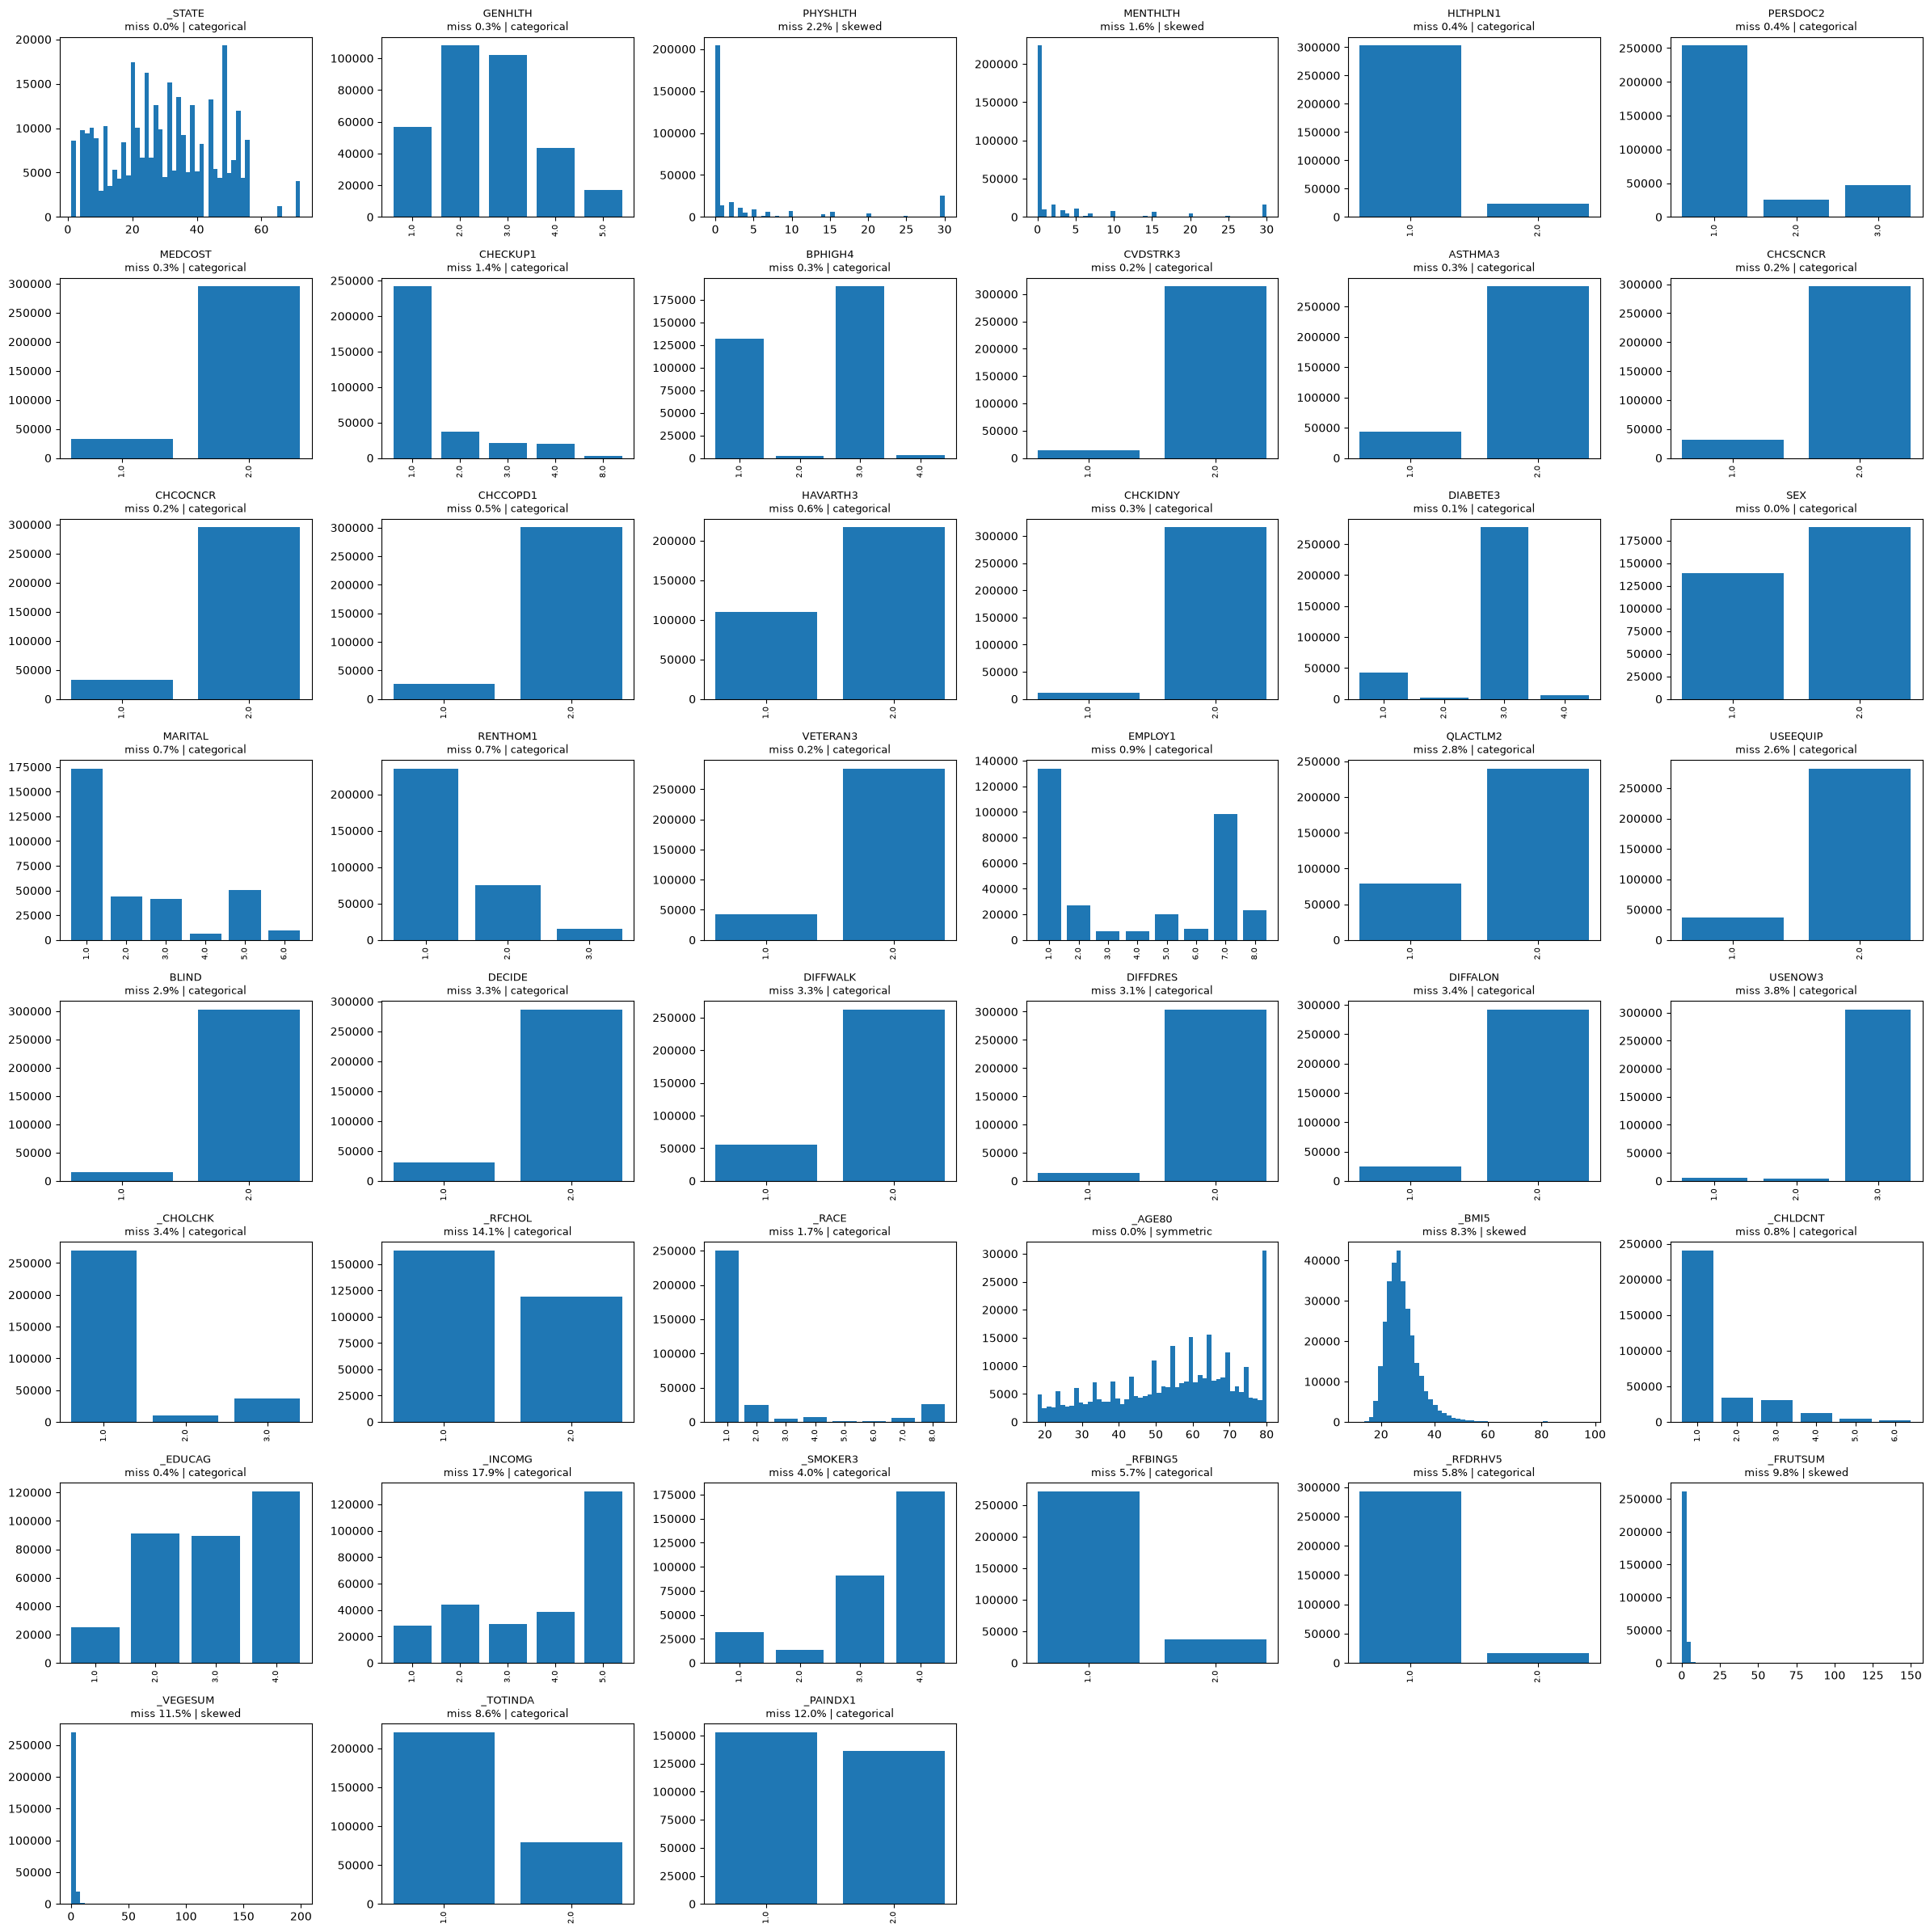

In [28]:
X = x_train_kept          # use TRAIN only to decide imputation
names = kept_feature_names

def skewness(v):
    s = v.std()
    return 0.0 if s == 0 else np.mean((v - v.mean()) ** 3) / s ** 3

summary = []
for j, name in enumerate(names):
    col = X[:, j]
    vals = col[~np.isnan(col)]
    miss = np.isnan(col).mean() * 100
    n_unique = len(np.unique(vals))
    sk = skewness(vals) if len(vals) else np.nan

    if is_categorical[j]:     # same decision as detect_categorical (+ manual fixes) above
        suggestion = "categorical -> mode or constant"
    elif abs(sk) > 1:
        suggestion = "skewed -> median"
    else:
        suggestion = "symmetric -> mean"
    summary.append((name, miss, n_unique, sk, suggestion))

# ---- printed table ----
print(f"{'feature':<10} {'miss%':>6} {'uniq':>6} {'skew':>7}  suggestion")
for name, miss, nu, sk, sug in summary:
    print(f"{name:<10} {miss:6.2f} {nu:6d} {sk:7.2f}  {sug}")

# ---- histograms ----
n_cols = 6
n_rows = int(np.ceil(len(names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows))
axes = axes.ravel()

for j, (name, miss, nu, sk, sug) in enumerate(summary):
    vals = X[:, j][~np.isnan(X[:, j])]
    ax = axes[j]
    if nu <= 30:   # discrete: one bar per value
        u, c = np.unique(vals, return_counts=True)
        ax.bar(u.astype(str), c)
        ax.tick_params(axis="x", labelrotation=90, labelsize=7)
    else:
        ax.hist(vals, bins=50)
    ax.set_title(f"{name}\nmiss {miss:.1f}% | {sug.split(' ->')[0]}", fontsize=9)

for ax in axes[len(names):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Categorical features

Categorical variables are encoded as one-hot indicators. Missing values are retained as a separate category rather than replaced by the most common observed level.

Categorical non-response can carry information, especially for sensitive questions such as income or health screening. We therefore encode missing categorical values as their own level (`-1`) and learn that level from the training data only.

In [ ]:
# Missing categorical values are kept as their own category. This preserves
# information in refusals or non-response instead of replacing it with the mode.

def column_mode(col):
    vals = col[~np.isnan(col)]
    uniq, counts = np.unique(vals, return_counts=True)
    return uniq[np.argmax(counts)]

cat_idx = np.nonzero(is_categorical)[0]

x_train_filled = x_train_kept.copy()
x_test_filled = x_test_kept.copy()

for j in cat_idx:
    x_train_filled[np.isnan(x_train_filled[:, j]), j] = -1.0
    x_test_filled[np.isnan(x_test_filled[:, j]), j] = -1.0

for j in cat_idx:
    missing_count = np.isnan(x_train_kept[:, j]).sum()
    print(f"{kept_feature_names[j]:<10} missing category = -1 ({missing_count} training rows)")

_STATE     mode = 20.0
GENHLTH    mode = 2.0
HLTHPLN1   mode = 1.0
PERSDOC2   mode = 1.0
MEDCOST    mode = 2.0
CHECKUP1   mode = 1.0
BPHIGH4    mode = 3.0
CVDSTRK3   mode = 2.0
ASTHMA3    mode = 2.0
CHCSCNCR   mode = 2.0
CHCOCNCR   mode = 2.0
CHCCOPD1   mode = 2.0
HAVARTH3   mode = 2.0
CHCKIDNY   mode = 2.0
DIABETE3   mode = 3.0
SEX        mode = 2.0
MARITAL    mode = 1.0
RENTHOM1   mode = 1.0
VETERAN3   mode = 2.0
EMPLOY1    mode = 1.0
QLACTLM2   mode = 2.0
USEEQUIP   mode = 2.0
BLIND      mode = 2.0
DECIDE     mode = 2.0
DIFFWALK   mode = 2.0
DIFFDRES   mode = 2.0
DIFFALON   mode = 2.0
USENOW3    mode = 3.0
_CHOLCHK   mode = 1.0
_RFCHOL    mode = 1.0
_RACE      mode = 1.0
_CHLDCNT   mode = 1.0
_EDUCAG    mode = 4.0
_INCOMG    mode = 5.0
_SMOKER3   mode = 4.0
_RFBING5   mode = 1.0
_RFDRHV5   mode = 1.0
_TOTINDA   mode = 1.0
_PAINDX1   mode = 1.0


### Numerical features

For numerical variables, missing values are imputed with a train-set median. The retained numeric columns are then clipped using train-set percentiles and standardized using train-set mean and standard deviation.

In [30]:
num_idx = np.nonzero(~is_categorical)[0]

x_train_filled = x_train_filled.copy()
x_test_filled = x_test_filled.copy()

# --- 1. special codes ---
# already handled in convert_raw_features: 77/99 -> NaN and 88 -> 0 for PHYSHLTH / MENTHLTH

# --- 2. median imputation (+ optional missing indicator) ---
medians = {j: np.nanmedian(x_train_filled[:, j]) for j in num_idx}
missing_flags_train, missing_flags_test, flag_names = [], [], []

for j in num_idx:
    miss_rate = np.isnan(x_train_filled[:, j]).mean()
    if miss_rate > 0.05:   # add indicator only when missingness is substantial
        missing_flags_train.append(np.isnan(x_train_filled[:, j]).astype(float))
        missing_flags_test.append(np.isnan(x_test_filled[:, j]).astype(float))
        flag_names.append(kept_feature_names[j] + "_missing")
    x_train_filled[np.isnan(x_train_filled[:, j]), j] = medians[j]
    x_test_filled[np.isnan(x_test_filled[:, j]), j] = medians[j]

# --- 3. clip outliers at 1st / 99th percentile ---
for j in num_idx:
    lo, hi = np.percentile(x_train_filled[:, j], [1, 99])
    x_train_filled[:, j] = np.clip(x_train_filled[:, j], lo, hi)
    x_test_filled[:, j] = np.clip(x_test_filled[:, j], lo, hi)

# --- 4. standardize numeric features ---
mu = x_train_filled[:, num_idx].mean(axis=0)
sigma = x_train_filled[:, num_idx].std(axis=0)
sigma[sigma == 0] = 1   # avoid dividing by zero for constant columns
x_train_num = (x_train_filled[:, num_idx] - mu) / sigma
x_test_num = (x_test_filled[:, num_idx] - mu) / sigma

# --- 5. one-hot encode categorical features ---
# Category codes are labels, not quantities (_STATE = 53 is not "more" than _STATE = 1),
# and raw codes up to ~72 make gradient descent diverge. Each category becomes a 0/1 column.
# The first (reference) level is dropped so the columns are not collinear with the bias.
# Levels are taken from TRAIN; a level that only appears in test gets all zeros.
onehot_train, onehot_test, onehot_names = [], [], []
for j in cat_idx:
    levels = np.unique(x_train_filled[:, j])
    for level in levels[1:]:
        onehot_train.append((x_train_filled[:, j] == level).astype(float))
        onehot_test.append((x_test_filled[:, j] == level).astype(float))
        onehot_names.append(f"{kept_feature_names[j]}={level:g}")

# --- final matrices: [standardized numeric | missing indicators | one-hot categorical] ---
x_train_filled = np.column_stack([x_train_num] + missing_flags_train + onehot_train)
x_test_filled = np.column_stack([x_test_num] + missing_flags_test + onehot_test)
final_feature_names = np.concatenate([kept_feature_names[num_idx], flag_names, onehot_names])

print(x_train_filled.shape, x_test_filled.shape)
print("numeric:", len(num_idx), " missing flags:", len(flag_names), " one-hot:", len(onehot_names))
print("NaNs left:", np.isnan(x_train_filled).sum(), np.isnan(x_test_filled).sum())
print("value range:", x_train_filled.min().round(2), "to", x_train_filled.max().round(2))

(328135, 140) (109379, 140)
numeric: 6  missing flags: 3  one-hot: 131
NaNs left: 0 0
value range: -2.14 to 3.99


> After imputation, clipping, scaling, and one-hot encoding, the final training and test matrices contain no missing values.

> Because the positive class is rare, accuracy alone would hide poor detection of heart-disease cases. The next section compares imbalance strategies using PR-AUC and threshold-tuned F1.

### Class imbalance

Target: _MICHD   total samples: 328135
  class   -1:  299160  (91.17%)
  class    1:   28975  ( 8.83%)
Imbalance ratio (majority / minority): 10.3 : 1


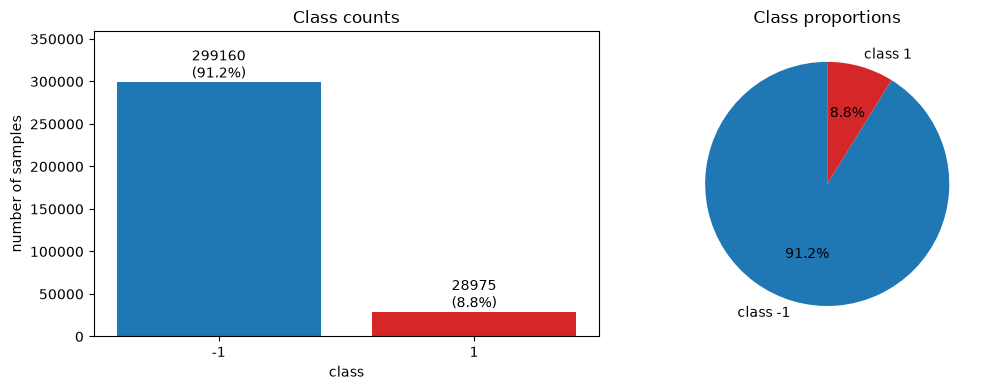

In [ ]:
y = y_train_raw[target_name]

classes, counts = np.unique(y, return_counts=True)
percent = counts / counts.sum() * 100

print(f"Target: {target_name}   total samples: {counts.sum()}")
for c, n, p in zip(classes, counts, percent):
    print(f"  class {c:>4g}: {n:>7d}  ({p:5.2f}%)")
print(f"Imbalance ratio (majority / minority): {counts.max() / counts.min():.1f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# bar chart with counts and percentages
bars = axes[0].bar([str(int(c)) for c in classes], counts, color=["tab:blue", "tab:red"][:len(classes)])
for b, n, p in zip(bars, counts, percent):
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{n}\n({p:.1f}%)",
                 ha="center", va="bottom", fontsize=10)
axes[0].set_title("Class counts")
axes[0].set_xlabel("class")
axes[0].set_ylabel("number of samples")
axes[0].set_ylim(0, counts.max() * 1.2)

# pie chart
axes[1].pie(counts, labels=[f"class {int(c)}" for c in classes], autopct="%1.1f%%",
            colors=["tab:blue", "tab:red"][:len(classes)], startangle=90)
axes[1].set_title("Class proportions")

plt.tight_layout()
plt.show()

The cited medical-data study reports a large recall gain for SMOTE at a fixed threshold. Our experiment shows the same pattern: resampling raises recall substantially at `0.5`, while threshold tuning brings F1 close to the baseline. This supports comparing both ranking metrics and threshold-dependent metrics rather than treating a fixed-threshold recall gain as a general performance improvement.

The comparison below evaluates several imbalance strategies under the same split and scoring protocol. The evaluation set remains untouched until final scoring.

### Comparing imbalance strategies

In [ ]:
def _knn(query, data, k, exclude_self=False):
    """Indices of the k nearest neighbours in `data` for each query row."""
    kk = k + 1 if exclude_self else k
    data_sq = np.sum(data ** 2, axis=1)
    batch = max(1, int(2e7 // data.shape[0]))
    out = np.empty((query.shape[0], kk), dtype=np.int64)
    for start in range(0, query.shape[0], batch):
        q = query[start:start + batch]
        distances = np.sum(q ** 2, axis=1)[:, None] + data_sq[None, :] - 2 * q @ data.T
        indices = np.argpartition(distances, kk - 1, axis=1)[:, :kk]
        rows = np.arange(indices.shape[0])[:, None]
        order = np.argsort(distances[rows, indices], axis=1)
        out[start:start + batch] = indices[rows, order]
    return out[:, 1:] if exclude_self else out


def _shuffle(X, y, rng):
    permutation = rng.permutation(len(y))
    return X[permutation], y[permutation]


def random_oversampling(X, y, ratio=1.0, seed=42):
    """Duplicate random minority samples until n_minority = ratio * n_majority."""
    rng = np.random.default_rng(seed)
    minority_idx, majority_idx = np.nonzero(y == 1)[0], np.nonzero(y == 0)[0]
    n_new = max(0, int(len(majority_idx) * ratio) - len(minority_idx))
    extra = rng.choice(minority_idx, n_new, replace=True)
    keep = np.concatenate([np.arange(len(y)), extra])
    return _shuffle(X[keep], y[keep], rng)


def smote(X, y, k=5, ratio=1.0, seed=42):
    """Create synthetic minority points between minority neighbours."""
    rng = np.random.default_rng(seed)
    x_minority = X[y == 1]
    n_new = max(0, int(np.sum(y == 0) * ratio) - len(x_minority))
    neighbours = _knn(x_minority, x_minority, k, exclude_self=True)

    base = rng.integers(0, len(x_minority), n_new)
    neighbour = neighbours[base, rng.integers(0, k, n_new)]
    gap = rng.random((n_new, 1))
    x_new = x_minority[base] + gap * (x_minority[neighbour] - x_minority[base])

    x_out = np.vstack([X, x_new])
    y_out = np.concatenate([y, np.ones(n_new, dtype=y.dtype)])
    return _shuffle(x_out, y_out, rng)


def adasyn(X, y, k=5, ratio=1.0, seed=42):
    """Generate more synthetic minority points near difficult observations."""
    rng = np.random.default_rng(seed)
    minority_idx = np.nonzero(y == 1)[0]
    x_minority = X[minority_idx]
    n_new = max(0, int(np.sum(y == 0) * ratio) - len(minority_idx))

    neighbours_all = _knn(x_minority, X, k, exclude_self=True)
    difficulty = np.mean(y[neighbours_all] == 0, axis=1)
    difficulty = (difficulty / difficulty.sum()
                  if difficulty.sum() > 0
                  else np.full(len(difficulty), 1 / len(difficulty)))
    generated = np.round(difficulty * n_new).astype(int)

    neighbours_minority = _knn(x_minority, x_minority, k, exclude_self=True)
    base = np.repeat(np.arange(len(x_minority)), generated)
    neighbour = neighbours_minority[base, rng.integers(0, k, len(base))]
    gap = rng.random((len(base), 1))
    x_new = x_minority[base] + gap * (x_minority[neighbour] - x_minority[base])

    x_out = np.vstack([X, x_new])
    y_out = np.concatenate([y, np.ones(len(base), dtype=y.dtype)])
    return _shuffle(x_out, y_out, rng)

## Comparing imbalance-handling methods

**Goal:** check whether resampling or class weighting improves a plain logistic-regression baseline on the imbalanced target.

### Setup
- **Three splits:** fit (60%), threshold (20%), and evaluation (20%), all stratified so the positive rate is comparable.
  - fit trains each model;
  - threshold selects the F1-optimal cutoff;
  - evaluation is used only for final reporting.
- **Resampling touches fit only.** Threshold and evaluation retain the real class distribution.
- **SMOTE/ADASYN output is snapped back to 0/1** on binary columns because interpolation otherwise creates fractional one-hot values.

### Model and metrics
Every method uses the same NumPy logistic-regression implementation and fixed optimization budget. The comparison reports PR-AUC as the primary metric, ROC-AUC as a secondary ranking metric, F1 at `0.5` for reference, and F1 at a threshold selected on the threshold split. A bootstrap interval is shown for PR-AUC; because methods use the same evaluation rows, paired bootstrap differences would be a stronger future comparison than separate intervals.

The preprocessing was fitted on the full labelled training set before these splits, so the experiment is suitable for method comparison but is not a completely leakage-free estimate of a future pipeline.

### How to read the results
Look at PR-AUC and the tuned F1 together. A gain at the fixed threshold can reflect calibration or class-prior changes rather than better ranking. The ROC and precision-recall plots show performance across thresholds.

fit: (196881, 140) positives: 0.0883
threshold: (65627, 140) positives: 0.0883
evaluation: (65627, 140) positives: 0.0883
Baseline       n_fit= 196881  PR-AUC=0.3823  ROC-AUC=0.8581  F1@0.5=0.2214  F1@tuned=0.4256  (37s)
Class weights  n_fit= 196881  PR-AUC=0.3806  ROC-AUC=0.8584  F1@0.5=0.3748  F1@tuned=0.4247  (38s)
Random over    n_fit= 269244  PR-AUC=0.3815  ROC-AUC=0.8585  F1@0.5=0.4198  F1@tuned=0.4254  (51s)
SMOTE          n_fit= 269244  PR-AUC=0.3775  ROC-AUC=0.8544  F1@0.5=0.4145  F1@tuned=0.4247  (54s)
ADASYN         n_fit= 265778  PR-AUC=0.3760  ROC-AUC=0.8537  F1@0.5=0.4130  F1@tuned=0.4229  (83s)

method           PR-AUC            95% CI  ROC-AUC   F1@0.5  precision   recall  tuned F1
Baseline         0.3823 [0.3697,0.3977]   0.8581   0.2214     0.5590   0.1381    0.4256
Random over      0.3815 [0.3687,0.3967]   0.8585   0.4198     0.3170   0.6214    0.4254
Class weights    0.3806 [0.3676,0.3952]   0.8584   0.3748     0.2438   0.8097    0.4247
SMOTE            0.3775 [0.3

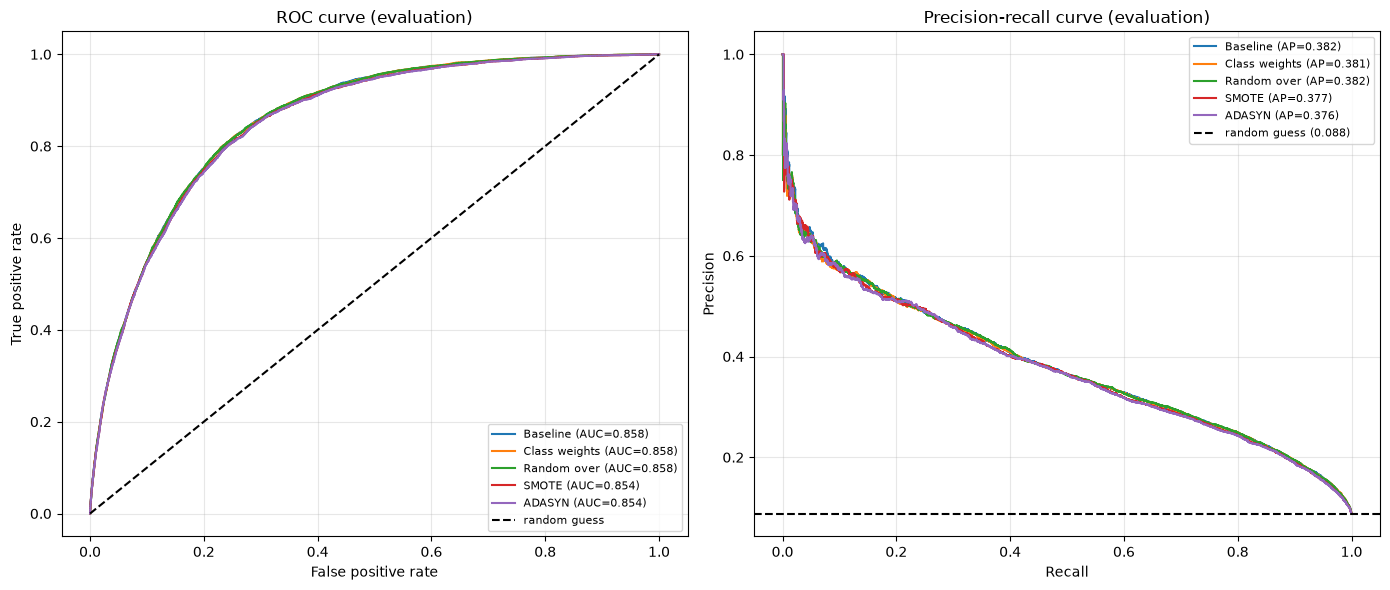

In [34]:
import sys
import time

sys.path.insert(0, str(PROJECT_DIR))
from implementations import reg_logistic_regression

# ---------------- data ----------------
X_all = np.asarray(x_train_filled, dtype=float)
Y_all = (np.asarray(y_train_raw[target_name]) == 1).astype(int)


def stratified_split(X, y, val_frac=0.2, seed=42):
    rng = np.random.default_rng(seed)
    is_val = np.zeros(len(y), dtype=bool)
    for class_value in np.unique(y):
        class_indices = rng.permutation(np.nonzero(y == class_value)[0])
        is_val[class_indices[:int(len(class_indices) * val_frac)]] = True
    return X[~is_val], y[~is_val], X[is_val], y[is_val]


# The evaluation split is never used to choose a threshold or train a model.
x_fit, y_fit, x_eval_pool, y_eval_pool = stratified_split(X_all, Y_all, val_frac=0.4)
x_threshold, y_threshold, x_eval, y_eval = stratified_split(
    x_eval_pool, y_eval_pool, val_frac=0.5, seed=43
)
print('fit:', x_fit.shape, 'positives:', y_fit.mean().round(4))
print('threshold:', x_threshold.shape, 'positives:', y_threshold.mean().round(4))
print('evaluation:', x_eval.shape, 'positives:', y_eval.mean().round(4))

# ---------------- logistic regression ----------------
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))


def fit_project_logreg(X, y, lambda_=1e-4, max_iters=2000, gamma=0.5):
    """Train with the official regularized logistic-regression implementation."""
    X_with_bias = np.column_stack([np.ones(len(X)), X])
    initial_weights = np.zeros(X_with_bias.shape[1])
    weights, loss = reg_logistic_regression(
        y, X_with_bias, lambda_, initial_weights, max_iters, gamma
    )
    return weights, loss


def fit_weighted_logreg(X, y, sample_weight, lambda_=1e-4, max_iters=2000, gamma=0.5):
    """Weighted counterpart used only because the official API has no weights."""
    X_with_bias = np.column_stack([np.ones(len(X)), X])
    weights = np.zeros(X_with_bias.shape[1])
    normalized_weight = sample_weight / sample_weight.mean()
    for _ in range(max_iters):
        probabilities = sigmoid(X_with_bias @ weights)
        gradient = X_with_bias.T @ (normalized_weight * (probabilities - y)) / len(y)
        gradient[1:] += lambda_ * weights[1:]
        weights -= gamma * gradient
    return weights, None


def predict_proba(X, weights):
    return sigmoid(np.column_stack([np.ones(len(X)), X]) @ weights)


# ---------------- metrics ----------------
def ranking_metrics(y_true, scores):
    """Return threshold-free ROC-AUC and average precision."""
    order = np.argsort(-scores, kind='mergesort')
    sorted_labels = y_true[order]
    sorted_scores = scores[order]
    last_of_group = np.r_[np.nonzero(np.diff(sorted_scores) != 0)[0], len(scores) - 1]
    true_positives = np.cumsum(sorted_labels)[last_of_group]
    false_positives = np.cumsum(1 - sorted_labels)[last_of_group]
    positives = true_positives[-1]
    negatives = false_positives[-1]

    recall = true_positives / positives
    precision = true_positives / np.maximum(true_positives + false_positives, 1)
    fpr = false_positives / negatives
    fpr0, recall0 = np.r_[0, fpr], np.r_[0, recall]
    roc_auc = np.sum(np.diff(fpr0) * (recall0[1:] + recall0[:-1]) / 2)
    average_precision = np.sum(np.diff(recall0) * precision)
    thresholds = sorted_scores[last_of_group]
    return {
        'roc_auc': roc_auc,
        'average_precision': average_precision,
        'precision_curve': precision,
        'recall_curve': recall,
        'fpr_curve': fpr,
        'thresholds': thresholds,
    }


def threshold_metrics(y_true, scores, threshold):
    predictions = scores >= threshold
    true_positives = np.sum(predictions & (y_true == 1))
    false_positives = np.sum(predictions & (y_true == 0))
    false_negatives = np.sum(~predictions & (y_true == 1))
    precision = true_positives / max(true_positives + false_positives, 1)
    recall = true_positives / max(true_positives + false_negatives, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    return {'precision': precision, 'recall': recall, 'f1': f1}


def best_f1_threshold(y_true, scores):
    ranking = ranking_metrics(y_true, scores)
    precision, recall = ranking['precision_curve'], ranking['recall_curve']
    f1_values = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return float(ranking['thresholds'][np.argmax(f1_values)])


def bootstrap_ap_interval(y_true, scores, n_boot=200, seed=0):
    """95% interval of average precision from resampling the evaluation rows."""
    rng = np.random.default_rng(seed)
    values = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].sum() == 0:
            continue
        values.append(ranking_metrics(y_true[idx], scores[idx])['average_precision'])
    return np.percentile(values, [2.5, 97.5])


# ---------------- methods to compare ----------------
OVER_RATIO = 0.5
n_pos, n_neg = y_fit.sum(), len(y_fit) - y_fit.sum()

binary_columns = {j: np.unique(x_fit[:, j]) for j in range(x_fit.shape[1])
                  if len(np.unique(x_fit[:, j])) == 2}


def snap_binary(X, y):
    X = X.copy()
    for j, (low, high) in binary_columns.items():
        X[:, j] = np.where(np.abs(X[:, j] - low) <= np.abs(X[:, j] - high), low, high)
    return X, y


methods = {
    'Baseline': lambda X, y: (X, y, None),
    'Class weights': lambda X, y: (X, y, np.where(y == 1, n_neg / n_pos, 1.0)),
    'Random over': lambda X, y: (*random_oversampling(X, y, ratio=OVER_RATIO), None),
    'SMOTE': lambda X, y: (*snap_binary(*smote(X, y, k=5, ratio=OVER_RATIO)), None),
    'ADASYN': lambda X, y: (*snap_binary(*adasyn(X, y, k=5, ratio=OVER_RATIO)), None),
}

# Resampling is applied to fit only. Threshold and evaluation keep the original distribution.
results = {}
for method_name, prepare in methods.items():
    start_time = time.time()
    X_method, y_method, sample_weight = prepare(x_fit, y_fit)
    if sample_weight is None:
        weights, loss = fit_project_logreg(X_method, y_method)
    else:
        weights, loss = fit_weighted_logreg(X_method, y_method, sample_weight)
    threshold_scores = predict_proba(x_threshold, weights)
    evaluation_scores = predict_proba(x_eval, weights)
    threshold = best_f1_threshold(y_threshold, threshold_scores)
    ranking = ranking_metrics(y_eval, evaluation_scores)
    ap_low, ap_high = bootstrap_ap_interval(y_eval, evaluation_scores)
    fixed_metrics = threshold_metrics(y_eval, evaluation_scores, 0.5)
    tuned_metrics = threshold_metrics(y_eval, evaluation_scores, threshold)
    results[method_name] = {
        **ranking,
        'ap_low': ap_low,
        'ap_high': ap_high,
        'threshold': threshold,
        'fixed_precision': fixed_metrics['precision'],
        'fixed_recall': fixed_metrics['recall'],
        'fixed_f1': fixed_metrics['f1'],
        'tuned_precision': tuned_metrics['precision'],
        'tuned_recall': tuned_metrics['recall'],
        'tuned_f1': tuned_metrics['f1'],
    }
    print(f"{method_name:<14} n_fit={len(y_method):>7}  "
          f"PR-AUC={ranking['average_precision']:.4f}  "
          f"ROC-AUC={ranking['roc_auc']:.4f}  "
          f"F1@0.5={fixed_metrics['f1']:.4f}  "
          f"F1@tuned={tuned_metrics['f1']:.4f}  "
          f"({time.time() - start_time:.0f}s)")

# ---------------- summary table ----------------
print(f"\n{'method':<14} {'PR-AUC':>8} {'95% CI':>17} {'ROC-AUC':>8} {'F1@0.5':>8} "
      f"{'precision':>10} {'recall':>8} {'tuned F1':>9}")
for method_name, metrics in sorted(
    results.items(), key=lambda item: -item[1]['average_precision']
):
    print(f"{method_name:<14} {metrics['average_precision']:8.4f} "
          f"[{metrics['ap_low']:.4f},{metrics['ap_high']:.4f}] "
          f"{metrics['roc_auc']:8.4f} {metrics['fixed_f1']:8.4f} "
          f"{metrics['fixed_precision']:10.4f} {metrics['fixed_recall']:8.4f} "
          f"{metrics['tuned_f1']:9.4f}")

# ---------------- plots ----------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for method_name, metrics in results.items():
    axes[0].plot(np.r_[0, metrics['fpr_curve']], np.r_[0, metrics['recall_curve']],
                 label=f"{method_name} (AUC={metrics['roc_auc']:.3f})")
    axes[1].plot(np.r_[0, metrics['recall_curve']], np.r_[1, metrics['precision_curve']],
                 label=f"{method_name} (AP={metrics['average_precision']:.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', label='random guess')
axes[0].set(title='ROC curve (evaluation)', xlabel='False positive rate', ylabel='True positive rate')
axes[1].axhline(y_eval.mean(), color='k', linestyle='--', label=f'random guess ({y_eval.mean():.3f})')
axes[1].set(title='Precision-recall curve (evaluation)', xlabel='Recall', ylabel='Precision')

for axis in axes:
    axis.legend(fontsize=8, loc='best')
    axis.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Conclusion about class imbalance

The comparison does not show a clear ranking improvement from resampling or class weighting: PR-AUC intervals overlap, and tuned F1 is close across methods. Resampling mainly changes the operating point, which explains the much higher recall at the default threshold of `0.5` without a comparable gain after threshold tuning.

For the reproducible prepared dataset, we therefore select the **baseline** model with its threshold tuned on the threshold split. It is simpler, avoids duplicated rows in later cross-validation, and performs comparably once the decision threshold is chosen. The saved threshold is learned from the model trained on the 60% fit split and reused as an approximation for the final full-data model; a future final evaluation should retune it within a validation scheme.

In [ ]:
# ---------------- save comparison results and selected data ----------------
# Save the metrics used to compare imbalance-handling methods.
# The final prepared data uses all labelled rows with the selected baseline method.

RESULTS_DIR = PROJECT_DIR / 'dataset' / 'prepared'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

method_names = np.array(list(results.keys()))
np.savez_compressed(
    RESULTS_DIR / 'imbalance_comparison_results.npz',
    method_names=method_names,
    pr_auc=np.array([results[name]['average_precision'] for name in method_names]),
    pr_auc_low=np.array([results[name]['ap_low'] for name in method_names]),
    pr_auc_high=np.array([results[name]['ap_high'] for name in method_names]),
    roc_auc=np.array([results[name]['roc_auc'] for name in method_names]),
    threshold=np.array([results[name]['threshold'] for name in method_names]),
    fixed_precision=np.array([results[name]['fixed_precision'] for name in method_names]),
    fixed_recall=np.array([results[name]['fixed_recall'] for name in method_names]),
    fixed_f1=np.array([results[name]['fixed_f1'] for name in method_names]),
    tuned_precision=np.array([results[name]['tuned_precision'] for name in method_names]),
    tuned_recall=np.array([results[name]['tuned_recall'] for name in method_names]),
    tuned_f1=np.array([results[name]['tuned_f1'] for name in method_names]),
)

selected_method = 'Baseline'
selected_threshold = float(results[selected_method]['threshold'])
x_train_selected = X_all.copy()
y_train_selected = Y_all.copy()
test_ids = np.asarray(x_test_raw['Id'], dtype=int)
assert len(test_ids) == len(x_test_filled)

np.savez_compressed(
    RESULTS_DIR / 'selected_baseline_dataset.npz',
    x_train=x_train_selected.astype(np.float32),
    y_train=y_train_selected,
    x_train_raw=X_all.astype(np.float32),
    y_train_raw=Y_all,
    x_test=np.asarray(x_test_filled, dtype=np.float32),
    test_ids=test_ids,
    feature_names=np.asarray(final_feature_names, dtype=str),
    selected_method=np.array(selected_method),
    threshold=np.array(selected_threshold),
)

print('Saved comparison results to:', RESULTS_DIR / 'imbalance_comparison_results.npz')
print('Saved selected data to:', RESULTS_DIR / 'selected_baseline_dataset.npz')
print('Selected method:', selected_method)
print('Selected threshold:', selected_threshold)
print('Selected training set:', x_train_selected.shape, 'positives:', y_train_selected.mean().round(4))

Saved comparison results to: /Users/mohamedzirar/Documents/year4/ML/ML_project1/dataset/prepared/imbalance_comparison_results.npz
Saved selected data to: /Users/mohamedzirar/Documents/year4/ML/ML_project1/dataset/prepared/selected_random_over_dataset.npz
Selected threshold: 0.5624385838214444
Selected training set: (448740, 140) positives: 0.3333
